# 01_data_spark: Pipeline CSV → Parquet và Benchmark


## 0. Cấu hình

In [1]:
import os, re, glob, json, time, threading, subprocess, sys, platform, gc
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
import numpy as np, pandas as pd, psutil
import matplotlib.pyplot as plt
import pyarrow.dataset as ds
from pyspark.sql import SparkSession, Window, functions as F, types as T
pd.set_option("display.width", 200)

# ---- Tham số của nhóm (ghi vào manifest để tái lập) ----
SEED = 42
TEST_ATTACK_RATIO = 0.05   # tỷ lệ tấn công trong tập test
DEDUP_BENIGN = False       # True = loại benign trùng trước khi chia (chống rò rỉ train/test). Nhóm chốt rồi đổi.
BENCH_REPEAT = 3           # số lần lặp mỗi truy vấn benchmark; giảm xuống 2 nếu thiếu thời gian
SPARK_MEM = os.environ.get("NBAIOT_SPARK_MEM", "16g")

# ---- Đường dẫn (tự tìm dataset gốc) ----
ROOT = os.environ.get("NBAIOT_ROOT")
if not ROOT:
    found = glob.glob("/kaggle/input/**/device_info.csv", recursive=True)
    assert found, "Chưa gắn dataset N-BaIoT: + Add Input → 'N-BaIoT Dataset to Detect IoT Botnet Attacks'"
    ROOT = os.path.dirname(found[0])
WORK = os.environ.get("NBAIOT_WORK", "/kaggle/working")
PQ = f"{WORK}/processed/nbaiot_parquet"
SPLIT = f"{WORK}/processed/nbaiot_split"
RES = f"{WORK}/results"
os.makedirs(RES, exist_ok=True)
print("Dataset gốc:", ROOT)

spark = (SparkSession.builder.appName("nbaiot_pipeline").master("local[*]")
         .config("spark.driver.memory", SPARK_MEM)
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

env = {"ngay_chay": time.strftime("%Y-%m-%d %H:%M"), "python": platform.python_version(),
       "pyspark": spark.version, "spark_master": spark.sparkContext.master,
       "driver_memory": SPARK_MEM, "cpu_cores": os.cpu_count(),
       "ram_total_GB": round(psutil.virtual_memory().total / 1e9, 1)}
pd.Series(env).to_csv(f"{RES}/moi_truong.csv", header=["gia_tri"])
pd.Series(env)

Dataset gốc: /kaggle/input/datasets/mkashifn/nbaiot-dataset


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 08:39:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


ngay_chay        2026-11-19 08:40
python                    3.13.16
pyspark                     4.0.4
spark_master             local[*]
driver_memory                 16g
cpu_cores                       4
ram_total_GB                 33.7
dtype: object

### Hàm đo thời gian và RAM

Đo **thời gian thực** (wall-clock) và **RAM đỉnh** của tiến trình Python cộng tiến trình Java (Spark) trong lúc
truy vấn chạy (lấy mẫu mỗi 0,1 giây). Lưu ý cho báo cáo: JVM giữ lại bộ nhớ đã cấp phát, nên RAM của Spark phản ánh
mức JVM đã chiếm, không phải dữ liệu thực sự cần.

In [2]:
def _rss_total():
    p = psutil.Process()
    tot = p.memory_info().rss
    for c in p.children(recursive=True):
        try:
            tot += c.memory_info().rss
        except psutil.Error:
            pass
    return tot

def measure(fn):
    """Chạy fn(), trả (kết quả, giây, RAM đỉnh MB, RAM tăng thêm MB)."""
    gc.collect()
    base = _rss_total(); peak = [base]; stop = threading.Event()
    def sampler():
        while not stop.is_set():
            peak[0] = max(peak[0], _rss_total()); stop.wait(0.1)
    th = threading.Thread(target=sampler, daemon=True); th.start()
    t0 = time.perf_counter()
    try:
        out = fn()
    finally:
        sec = time.perf_counter() - t0; stop.set(); th.join()
    peak[0] = max(peak[0], _rss_total())
    return out, sec, peak[0] / 1e6, (peak[0] - base) / 1e6

def dir_size(path):
    if os.path.isfile(path):
        return os.path.getsize(path)
    return sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(path) for f in fs)

## 1. Pipeline: liệt kê file và gắn nhãn từ tên file

In [3]:
PAT = re.compile(r"^(\d+)\.(benign|gafgyt|mirai)(?:\.(\w+))?\.csv$")
meta = []
for f in sorted(os.listdir(ROOT)):
    m = PAT.match(f)
    if m:
        dev, fam, att = m.groups()
        meta.append({"file": f, "device_id": int(dev), "family": fam,
                     "attack_type": att or "none", "bytes": os.path.getsize(os.path.join(ROOT, f))})
meta = pd.DataFrame(meta)
CSV_PATHS = [os.path.join(ROOT, f) for f in meta.file]

# Kiểm tra: mọi file có cùng header
headers = {open(p).readline().strip() for p in CSV_PATHS}
assert len(headers) == 1, f"Các file có {len(headers)} kiểu header khác nhau"
RAW_COLS = headers.pop().split(",")
FEAT = [c.replace(".", "_") for c in RAW_COLS]        # tên đã đổi dấu chấm thành gạch dưới
RAW_SCHEMA = T.StructType([T.StructField(c, T.DoubleType()) for c in RAW_COLS])

print(f"File dữ liệu: {len(meta)} | thiết bị: {meta.device_id.nunique()} | đặc trưng: {len(FEAT)}")
print(f"Dung lượng CSV: {meta.bytes.sum()/1e9:.2f} GB")
print(meta.groupby(["device_id", "family"]).size().unstack(fill_value=0))

File dữ liệu: 89 | thiết bị: 9 | đặc trưng: 115
Dung lượng CSV: 8.14 GB
family     benign  gafgyt  mirai
device_id                       
1               1       5      5
2               1       5      5
3               1       5      0
4               1       5      5
5               1       5      5
6               1       5      5
7               1       5      0
8               1       5      5
9               1       5      5


## 2. Pipeline: CSV → Parquet (partition theo `device_id`)

Đọc với **schema khai báo sẵn** (115 cột `double`) thay vì `inferSchema`, nên Spark không phải quét dữ liệu hai lần.
Nhãn lấy từ tên file qua `input_file_name()`.

In [4]:
def build_labeled(spark):
    raw = spark.read.option("header", True).schema(RAW_SCHEMA).csv(CSV_PATHS).toDF(*FEAT)
    src = F.input_file_name()
    fam = F.regexp_extract(src, r"/\d+\.(benign|gafgyt|mirai)[^/]*\.csv$", 1)
    return (raw
        .withColumn("device_id", F.regexp_extract(src, r"/(\d+)\.(?:benign|gafgyt|mirai)[^/]*\.csv$", 1).cast("int"))
        .withColumn("family", fam)
        .withColumn("attack_type", F.when(fam == "benign", F.lit("none"))
                    .otherwise(F.regexp_extract(src, r"/\d+\.(?:gafgyt|mirai)\.(\w+)\.csv$", 1)))
        .withColumn("label", F.when(fam == "benign", 0).otherwise(1)))

_, t_ingest, ram_ingest, _ = measure(lambda: build_labeled(spark)
                                     .write.mode("overwrite").partitionBy("device_id").parquet(PQ))
pq_files = glob.glob(f"{PQ}/**/*.parquet", recursive=True)
print(f"Ghi Parquet: {t_ingest:.1f} giây | RAM đỉnh {ram_ingest:,.0f} MB | "
      f"{len(pq_files)} file | {dir_size(PQ)/1e9:.2f} GB")

Ghi Parquet: 223.3 giây | RAM đỉnh 6,235 MB | 105 file | 2.64 GB


## 3. Pipeline: kiểm tra Parquet với `data_summary.csv`

In [5]:
df = spark.read.parquet(PQ)

ref = pd.read_csv(f"{ROOT}/data_summary.csv", skipinitialspace=True)
ref.columns = ["file", "so_dong_goc", "so_dac_trung"]
ref = ref.merge(meta[["file", "device_id", "family", "attack_type"]], on="file")
ref = ref.groupby(["device_id", "family", "attack_type"], as_index=False).so_dong_goc.sum()

got = df.groupBy("device_id", "family", "attack_type").count().toPandas()
chk = ref.merge(got, on=["device_id", "family", "attack_type"], how="outer")
chk["khop"] = chk.so_dong_goc == chk["count"]
chk.to_csv(f"{RES}/pipeline_doi_chieu.csv", index=False)

nulls = df.select(sum(F.col(c).isNull().cast("int") for c in FEAT).alias("n")).agg(F.sum("n")).first()[0]
checks = {
    "89 file dữ liệu": len(meta) == 89,
    "9 thiết bị": df.select("device_id").distinct().count() == 9,
    "119 cột (115 đặc trưng + 4 nhãn)": len(df.columns) == 119,
    "số dòng khớp data_summary ở mọi (thiết bị, loại)": bool(chk.khop.all()),
    "không có giá trị rỗng": nulls == 0,
    "label chỉ 0/1": set(r[0] for r in df.select("label").distinct().collect()) <= {0, 1},
}
print("Tổng số dòng:", int(chk["count"].sum()), "| UCI công bố: 7.062.606")
for k, v in checks.items():
    print(("ĐẠT  " if v else "LỖI  ") + k)
if not chk.khop.all():
    print(chk[~chk.khop].to_string(index=False))

Tổng số dòng: 7062606 | UCI công bố: 7.062.606
ĐẠT  89 file dữ liệu
ĐẠT  9 thiết bị
ĐẠT  119 cột (115 đặc trưng + 4 nhãn)
ĐẠT  số dòng khớp data_summary ở mọi (thiết bị, loại)
ĐẠT  không có giá trị rỗng
ĐẠT  label chỉ 0/1


## 4. Pipeline: chia train / val / test

In [6]:
PAPER = f"{WORK}/processed/nbaiot_paper"

ordered = build_labeled(spark).withColumn("row_id", F.monotonically_increasing_id())   # tăng theo thứ tự dòng trong từng file

w_p = Window.partitionBy("device_id")
ben_p = (ordered.filter("label = 0")
    .withColumn("_rn", F.row_number().over(w_p.orderBy("row_id")))
    .withColumn("_n", F.count("*").over(w_p))
    .withColumn("split", F.when(F.col("_rn") <= F.floor(F.col("_n") / 3), "train")
                          .when(F.col("_rn") <= F.floor(F.col("_n") * 2 / 3), "val")
                          .otherwise("test"))
    .drop("_rn", "_n"))
att_p = ordered.filter("label = 1").withColumn("split", F.lit("test"))      # toàn bộ tấn công vào test

_, t_paper, ram_paper, _ = measure(lambda: ben_p.unionByName(att_p)
                                   .write.mode("overwrite").partitionBy("device_id").parquet(PAPER))
print(f"Ghi nbaiot_paper: {t_paper:.1f} giây | RAM đỉnh {ram_paper:,.0f} MB | {dir_size(PAPER)/1e9:.2f} GB")

Ghi nbaiot_paper: 327.4 giây | RAM đỉnh 7,638 MB | 2.67 GB


In [7]:
# Kiểm tra 1: row_id đúng thứ tự dòng trong file gốc (so với pandas đọc trực tiếp từ CSV)
sp_p = spark.read.parquet(PAPER)

def check_order(fname, cols=(0, 57)):
    r = meta[meta.file == fname].iloc[0]
    got = (sp_p.filter(f"device_id = {r.device_id} AND family = '{r.family}' AND attack_type = '{r.attack_type}'")
                .orderBy("row_id").select(*[FEAT[i] for i in cols]).toPandas())
    ref = pd.read_csv(f"{ROOT}/{fname}", usecols=[RAW_COLS[i] for i in cols])
    ok = len(got) == len(ref) and all(
        np.allclose(got[FEAT[i]].values, ref[RAW_COLS[i]].values, rtol=1e-9, atol=0, equal_nan=True) for i in cols)
    print(("ĐẠT  " if ok else "LỖI  ") + f"{fname}: {len(ref):,} dòng")
    return ok

biggest = meta.sort_values("bytes").file.iloc[-1]          # file lớn nhất bị Spark cắt thành nhiều phần nhất
oks = [check_order("1.benign.csv"), check_order(biggest)]
assert all(oks), ("row_id không khớp thứ tự file gốc: không dùng được nbaiot_paper cho bỏ phiếu theo cửa sổ. "
                  "Cách khắc phục: đọc từng file bằng pandas, gán row_id = 0..n-1 rồi ghi Parquet.")

# Kiểm tra 2: số dòng từng thiết bị, đủ 7.062.606 dòng
cnt = sp_p.groupBy("device_id", "split", "label").count().toPandas()
cnt["nhom"] = cnt["split"] + "_" + cnt["label"].map({0: "benign", 1: "tan_cong"})
tab = cnt.pivot(index="device_id", columns="nhom", values="count").fillna(0).astype(int)
tab["tong"] = tab.sum(axis=1)
tab.to_csv(f"{RES}/split_paper_summary.csv"); tab.to_csv(f"{WORK}/processed/split_paper_summary.csv")
print(tab.to_string())
print("Tổng số dòng:", int(tab.tong.sum()), "| UCI công bố: 7.062.606")
assert int(tab.tong.sum()) == 7062606
assert (tab.filter(like="train_tan_cong").sum().sum() == 0) and (tab.filter(like="val_tan_cong").sum().sum() == 0)

man_p = {"cach_chia": "paper N-BaIoT: benign theo thứ tự dòng 1/3 train, 1/3 val (DSopt), 1/3 test; toàn bộ tấn công vào test",
         "feature_columns": FEAT, "label_columns": ["device_id", "family", "attack_type", "label", "row_id", "split"],
         "ghi_chu": "row_id chỉ so sánh được trong cùng (device_id, family, attack_type); giả định file CSV theo thứ tự thời gian",
         "tong_dong": int(tab.tong.sum()), "ngay_tao": env["ngay_chay"]}
with open(f"{WORK}/processed/manifest_paper.json", "w", encoding="utf-8") as f:
    json.dump(man_p, f, ensure_ascii=False, indent=2)
print("Đã ghi processed/nbaiot_paper và processed/manifest_paper.json")

ĐẠT  1.benign.csv: 49,548 dòng
ĐẠT  1.mirai.udp.csv: 237,665 dòng


nhom       test_benign  test_tan_cong  train_benign  val_benign     tong
device_id                                                               
1                16516         968750         16516       16516  1018298
2                 4371         822763          4371        4371   835876
3                13034         316400         13033       13033   355500
4                58414         923437         58413       58413  1098677
5                20718         766106         20718       20718   828260
6                32838         738377         32838       32838   836891
7                17384         323072         17383       17383   375222
8                15529         816471         15528       15528   863056
9                 6510         831298          6509        6509   850826
Tổng số dòng: 7062606 | UCI công bố: 7.062.606
Đã ghi processed/nbaiot_paper và processed/manifest_paper.json


## 5. Benchmark: CSV và Parquet

| Truy vấn | Ý nghĩa |
| --- | --- |
| Q1 đếm toàn bộ | quét hết dữ liệu (Parquet đọc số dòng từ metadata) |
| Q2 trung bình 3 cột | chỉ cần 3/115 cột: Parquet đọc theo cột, CSV vẫn phải đọc cả dòng |
| Q3 lọc 1 thiết bị | Parquet bỏ qua thư mục các thiết bị khác (partition pruning); CSV phải đọc mọi file rồi lọc |
| P1, P2 (pandas) | đọc dữ liệu thiết bị 1 vào pandas: toàn bộ cột, và chỉ 3 cột |

Mỗi truy vấn chạy `BENCH_REPEAT` lần. Lần đầu có thể chậm hơn do đọc từ đĩa mạng của Kaggle; báo cáo dùng **trung vị**.
Cả hai định dạng đều đọc bằng schema khai báo sẵn, để so sánh công bằng.

**Cột RAM:** với Spark dùng `ram_dinh_MB` (Python + JVM; JVM giữ bộ nhớ đã cấp nên con số tăng dần, không giảm).
Với pandas dùng `dataframe_MB` (dung lượng DataFrame thực tế trong RAM), chính xác hơn đo theo tiến trình.

In [8]:
C3 = ["MI_dir_L5_weight", "H_L5_mean", "HH_L5_std"]
csv_df = lambda: spark.read.option("header", True).schema(RAW_SCHEMA).csv(CSV_PATHS)
pq_df = lambda: spark.read.parquet(PQ)
dev1_csv = [p for p in CSV_PATHS if os.path.basename(p).startswith("1.")]

def pd_csv(usecols=None):
    return pd.concat([pd.read_csv(p, usecols=usecols) for p in dev1_csv], ignore_index=True)
def pd_parquet(columns=None):
    return ds.dataset(PQ, format="parquet", partitioning="hive").to_table(
        columns=columns, filter=ds.field("device_id") == 1).to_pandas()

TASKS = [
    ("Spark", "Q1 đếm toàn bộ",      "CSV",     lambda: csv_df().count()),
    ("Spark", "Q1 đếm toàn bộ",      "Parquet", lambda: pq_df().count()),
    ("Spark", "Q2 trung bình 3 cột", "CSV",     lambda: csv_df().agg(*[F.avg(c) for c in C3]).collect()),
    ("Spark", "Q2 trung bình 3 cột", "Parquet", lambda: pq_df().agg(*[F.avg(c) for c in C3]).collect()),
    ("Spark", "Q3 lọc thiết bị 1",   "CSV",     lambda: csv_df().filter(F.input_file_name().rlike(r"/1\.[a-z]+[^/]*\.csv$")).count()),
    ("Spark", "Q3 lọc thiết bị 1",   "Parquet", lambda: pq_df().filter("device_id = 1").count()),
    ("pandas", "P1 thiết bị 1, 115 cột", "CSV",     lambda: pd_csv()),
    ("pandas", "P1 thiết bị 1, 115 cột", "Parquet", lambda: pd_parquet()),
    ("pandas", "P2 thiết bị 1, 3 cột",   "CSV",     lambda: pd_csv(C3)),
    ("pandas", "P2 thiết bị 1, 3 cột",   "Parquet", lambda: pd_parquet(C3)),
]

runs = []
for tool, q, fmt, fn in TASKS:
    for i in range(1, BENCH_REPEAT + 1):
        out, sec, peak, delta = measure(fn)
        is_df = isinstance(out, pd.DataFrame)
        df_mb = out.memory_usage(deep=True).sum() / 1e6 if is_df else np.nan
        runs.append({"cong_cu": tool, "truy_van": q, "dinh_dang": fmt, "lan": i,
                     "so_dong": len(out) if is_df else (out if np.isscalar(out) else np.nan),
                     "giay": round(sec, 2), "ram_dinh_MB": round(peak), "ram_tang_MB": round(delta),
                     "dataframe_MB": round(df_mb, 1)})
        del out; gc.collect()
        ram = f"DataFrame {df_mb:8,.0f} MB" if is_df else f"RAM đỉnh {peak:8,.0f} MB"
        print(f"{tool:6s} | {q:24s} | {fmt:7s} | lần {i}: {sec:7.2f} s | {ram}")
runs = pd.DataFrame(runs)
runs.to_csv(f"{RES}/benchmark_chi_tiet.csv", index=False)

Spark  | Q1 đếm toàn bộ           | CSV     | lần 1:    8.67 s | RAM đỉnh    4,004 MB


Spark  | Q1 đếm toàn bộ           | CSV     | lần 2:    8.75 s | RAM đỉnh    4,007 MB


Spark  | Q1 đếm toàn bộ           | CSV     | lần 3:    8.50 s | RAM đỉnh    4,010 MB
Spark  | Q1 đếm toàn bộ           | Parquet | lần 1:    0.42 s | RAM đỉnh    4,011 MB
Spark  | Q1 đếm toàn bộ           | Parquet | lần 2:    0.37 s | RAM đỉnh    4,015 MB
Spark  | Q1 đếm toàn bộ           | Parquet | lần 3:    0.37 s | RAM đỉnh    4,025 MB


Spark  | Q2 trung bình 3 cột      | CSV     | lần 1:   28.15 s | RAM đỉnh    4,028 MB


Spark  | Q2 trung bình 3 cột      | CSV     | lần 2:   27.84 s | RAM đỉnh    4,017 MB


Spark  | Q2 trung bình 3 cột      | CSV     | lần 3:   28.18 s | RAM đỉnh    4,006 MB


Spark  | Q2 trung bình 3 cột      | Parquet | lần 1:    1.01 s | RAM đỉnh    4,015 MB
Spark  | Q2 trung bình 3 cột      | Parquet | lần 2:    0.61 s | RAM đỉnh    4,018 MB
Spark  | Q2 trung bình 3 cột      | Parquet | lần 3:    0.65 s | RAM đỉnh    4,019 MB


Spark  | Q3 lọc thiết bị 1        | CSV     | lần 1:   11.49 s | RAM đỉnh    4,024 MB


Spark  | Q3 lọc thiết bị 1        | CSV     | lần 2:   11.31 s | RAM đỉnh    4,027 MB


Spark  | Q3 lọc thiết bị 1        | CSV     | lần 3:   11.28 s | RAM đỉnh    4,030 MB
Spark  | Q3 lọc thiết bị 1        | Parquet | lần 1:    0.18 s | RAM đỉnh    4,032 MB
Spark  | Q3 lọc thiết bị 1        | Parquet | lần 2:    0.17 s | RAM đỉnh    4,035 MB
Spark  | Q3 lọc thiết bị 1        | Parquet | lần 3:    0.22 s | RAM đỉnh    4,056 MB
pandas | P1 thiết bị 1, 115 cột   | CSV     | lần 1:   17.93 s | DataFrame      937 MB
pandas | P1 thiết bị 1, 115 cột   | CSV     | lần 2:   17.90 s | DataFrame      937 MB
pandas | P1 thiết bị 1, 115 cột   | CSV     | lần 3:   17.85 s | DataFrame      937 MB
pandas | P1 thiết bị 1, 115 cột   | Parquet | lần 1:    1.21 s | DataFrame    1,054 MB
pandas | P1 thiết bị 1, 115 cột   | Parquet | lần 2:    0.82 s | DataFrame    1,054 MB
pandas | P1 thiết bị 1, 115 cột   | Parquet | lần 3:    0.88 s | DataFrame    1,054 MB
pandas | P2 thiết bị 1, 3 cột     | CSV     | lần 1:    9.54 s | DataFrame       24 MB
pandas | P2 thiết bị 1, 3 cột     | CSV     | l

In [9]:
# Bảng benchmark đầu tiên (dán vào sheet "Số liệu")
bench = (runs.groupby(["cong_cu", "truy_van", "dinh_dang"], sort=False)
             .agg(giay_trung_vi=("giay", "median"), giay_lan_dau=("giay", "first"),
                  ram_dinh_MB=("ram_dinh_MB", "max"), ram_tang_MB=("ram_tang_MB", "max"),
                  dataframe_MB=("dataframe_MB", "first"))
             .reset_index())
wide = bench.pivot_table(index=["cong_cu", "truy_van"], columns="dinh_dang", values="giay_trung_vi", sort=False)
wide["nhanh_hon_x_lan"] = (wide["CSV"] / wide["Parquet"]).round(1)
bench.to_csv(f"{RES}/benchmark_csv_vs_parquet.csv", index=False)

pq_dev1 = dir_size(f"{PQ}/device_id=1")
size = pd.DataFrame([
    {"pham_vi": "Toàn bộ 9 thiết bị", "CSV_GB": meta.bytes.sum() / 1e9, "Parquet_GB": dir_size(PQ) / 1e9,
     "so_file_CSV": len(meta), "so_file_Parquet": len(glob.glob(f"{PQ}/**/*.parquet", recursive=True))},
    {"pham_vi": "Thiết bị 1", "CSV_GB": sum(map(os.path.getsize, dev1_csv)) / 1e9, "Parquet_GB": pq_dev1 / 1e9,
     "so_file_CSV": len(dev1_csv), "so_file_Parquet": len(glob.glob(f"{PQ}/device_id=1/*.parquet"))},
])
size["ty_le_nen"] = (size.CSV_GB / size.Parquet_GB).round(1)
size[["CSV_GB", "Parquet_GB"]] = size[["CSV_GB", "Parquet_GB"]].round(3)
size.to_csv(f"{RES}/benchmark_kich_thuoc.csv", index=False)

print("=== Thời gian (giây, trung vị) ===");   print(wide.to_string())
print("\n=== Chi tiết thời gian và RAM ===");   print(bench.to_string(index=False))
print("\n=== Kích thước ===");                  print(size.to_string(index=False))
print(f"\nPipeline CSV → Parquet: {t_ingest:.1f} giây, RAM đỉnh {ram_ingest:,.0f} MB")

=== Thời gian (giây, trung vị) ===
dinh_dang                         CSV  Parquet  nhanh_hon_x_lan
cong_cu truy_van                                               
Spark   Q1 đếm toàn bộ           8.67     0.37             23.4
        Q2 trung bình 3 cột     28.15     0.65             43.3
        Q3 lọc thiết bị 1       11.31     0.18             62.8
pandas  P1 thiết bị 1, 115 cột  17.90     0.88             20.3
        P2 thiết bị 1, 3 cột     9.33     0.03            311.0

=== Chi tiết thời gian và RAM ===
cong_cu               truy_van dinh_dang  giay_trung_vi  giay_lan_dau  ram_dinh_MB  ram_tang_MB  dataframe_MB
  Spark         Q1 đếm toàn bộ       CSV           8.67          8.67         4010            7           NaN
  Spark         Q1 đếm toàn bộ   Parquet           0.37          0.42         4025           10           NaN
  Spark    Q2 trung bình 3 cột       CSV          28.15         28.15         4028            2           NaN
  Spark    Q2 trung bình 3 cột   Parquet  

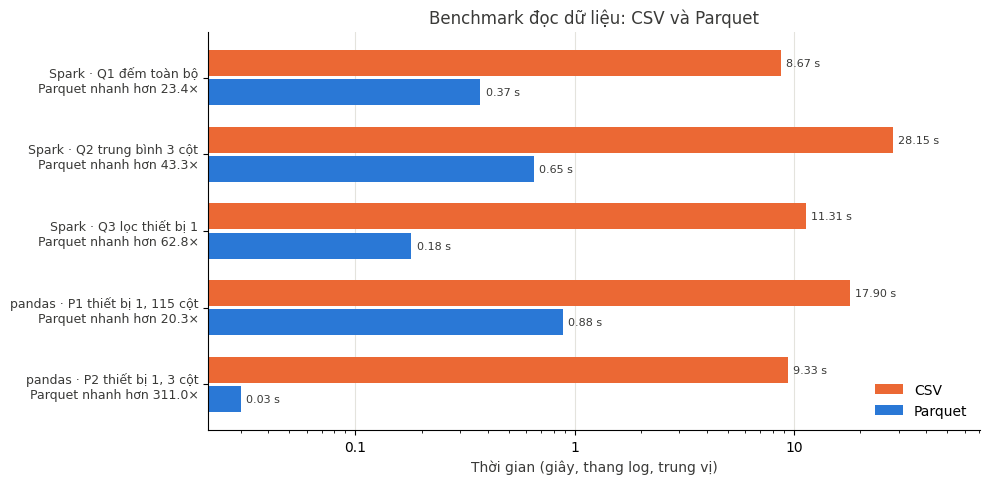

Đã lưu: ['benchmark_chi_tiet.csv', 'benchmark_csv_vs_parquet.csv', 'benchmark_kich_thuoc.csv', 'benchmark_thoi_gian.png', 'moi_truong.csv', 'pipeline_doi_chieu.csv', 'split_paper_summary.csv']


In [10]:
# Biểu đồ: thời gian trung vị theo truy vấn, CSV và Parquet cạnh nhau
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#3a3a38"
labels = [f"{t} · {q}\nParquet nhanh hơn {x}×" for (t, q), x in zip(wide.index, wide["nhanh_hon_x_lan"])]
y = np.arange(len(labels)); h = 0.38
fig, ax = plt.subplots(figsize=(10, 0.75 * len(labels) + 1.2))
for off, fmt, col in [(-h / 2, "CSV", ORANGE), (h / 2, "Parquet", BLUE)]:
    vals = wide[fmt].values
    ax.barh(y + off, vals, height=h - 0.04, color=col, label=fmt)
    for yi, v in zip(y + off, vals):
        ax.annotate(f"{v:.2f} s", (v, yi), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK)
ax.set_yticks(y, labels, fontsize=9, color=INK); ax.invert_yaxis()
ax.set_xscale("log")
from matplotlib.ticker import FuncFormatter
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(right=wide[["CSV", "Parquet"]].values.max() * 2.5); ax.set_xlabel("Thời gian (giây, thang log, trung vị)", color=INK)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e4e3dd"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Benchmark đọc dữ liệu: CSV và Parquet", color=INK)
fig.tight_layout(); fig.savefig(f"{RES}/benchmark_thoi_gian.png", dpi=130, bbox_inches="tight"); plt.show()
print("Đã lưu:", sorted(f for f in os.listdir(RES) if f.startswith(("benchmark", "pipeline", "split", "moi_truong"))))